# Pegasus with worker pools: a prototype

Every service of the testbed runs a **pool** of workers: `parallelism` workers take items from one FIFO queue, and up to
that many items are processed at the same time. Today's Pegasus models every service as one FIFO server, and its GP takes
`parallelism` as an input like any other knob. This notebook prototypes the alternative: a service is a FIFO pool of
c workers, with c = `parallelism`, and the GP no longer takes `parallelism` as an input. The reason is that the number of
workers should change how many items are served at the same time, not how long one item takes.

The notebook answers two questions on the chains of the testbed campaign:

1. Which execution-time model works without `parallelism` as an input: one trained only on runs with more cores than
   workers, one trained on every run, or one that also knows the load per worker? (Section 3)
2. Do the bounds of Pegasus hold, and how tight are they, when the services are pools? (Section 4)

This is a prototype on the branch `multi-server`. Its code is in `pegasus/multi_server.py`; no other notebook or module
uses it, and today's results in `2_evaluation.ipynb` do not change. Today's model and bounds are computed here with the
same functions as in `2_evaluation.ipynb`.

Terms used throughout:

- **Worker**: one of the c processes of a service, each handling one item at a time. **Pool**: the c workers of a
  service with their shared FIFO queue.
- **X**: the execution time of one item at one service, in seconds, from when a worker starts the item until the
  worker finishes it (the campaign's processing time).
- **λ**: the arrival rate of items at the chain, in items/s. Every node of a chain receives every item, so every node
  sees λ.
- **Load per worker**: λ / c, in items/s per worker.
- **Utilization of a pool**: λ · E[X] / c, the share of time an average worker is busy; a pool is overloaded at 1 or
  above.
- **α**: the violation probability ε. A bound at α bounds the (1 − α) quantile of the end-to-end latency, which is
  the p95 for α = 0.05.
- **Case**: one chain under one seed. A bound **holds** in a case if it covers at least the share `confidence` of
  the runs of the chain. A run counts as covered unless its bound lies below the lower edge of the confidence interval
  of the measured quantile, as in `2_evaluation.ipynb`.
- **The rule**: every node of a run has more cores than workers (cores > `parallelism`).

## 1. Setup

The parameters are those of B.1 in `2_evaluation.ipynb` (α, confidence, seeds, utilization of the busiest service).
The chains are every chain of the campaign (experiments `04a` to `04h`).

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.exceptions import ConvergenceWarning

from pegasus.bounds import martingale_closed_form_node_bounds, network_service_bound
from pegasus.evaluation import fit_services, pegasus_bound, pegasus_snc_bound
from pegasus.multi_server import (MODELS, campaign_rates, case_statistics, chain_servers, fifo_pool_chain_latencies, lane_martingale_node_bounds,
                                  lane_network_bound, load_response, model_beliefs, pool_truth, utilization_rates)
from pegasus.real_data import chain_execution_moments, chain_path, real_chain_data
from pegasus.simulation import fifo_chain_latencies

warnings.simplefilter("ignore", ConvergenceWarning)   # some GP hyperparameters end at their bounds, and scikit-learn warns for every such fit

alpha = 0.05                                           # violation probability epsilon: the bounds bound the (1 - alpha) latency quantile
confidence = 0.95                                      # a bound holds in a case if it covers this share of runs; also the confidence of the pessimistic mean
coverage_check = dict(n_batches=10, confidence=0.95)   # confidence interval of a measured quantile (batch means)
seed, seeds = 35, list(range(10))                      # base seed and seeds of 2_evaluation.ipynb
utilization = 0.5                                      # utilization of the busiest pool of every run in the setting "B.1 load"
chains = ["04a-chain-anomaly-agg", "04b-chain-camera-qr", "04c-chain-logs-tables", "04d-chain-lidar-agg", "04e-chain-qr-cv-face",
          "04f-chain-audio-anomaly-agg", "04g-chain-logs-signer-tables-idx", "04h-chain-camera-face-cv-signer-agg"]
output = Path("../../statics/tsc")                     # where the tables of the results are written
p_label = f"p{100 * (1 - alpha):g}"
short = lambda chain: chain.split("-", 1)[0]           # "04e-chain-qr-cv-face" -> "04e"

# one color per execution-time model, in the order of MODELS (categorical slots of a colorblind-checked palette); gray for references
MODEL_COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
REFERENCE_COLOR = "#8a8a85"

## 2. Ground truth: chains of worker pools

For every valid run of a chain, the campaign measured X for every request at every node. The ground truth replays these
measurements: each of `n_items` emulated items draws one measured request (its times at all nodes together), and the
items arrive as a Poisson process at rate λ. Every node is a FIFO pool with c = `parallelism` workers of that run. An
item starts at the earliest time at which it has arrived and a worker is free. Items can overtake each other: a short
item can finish before a long item that started earlier on another worker. So every node receives the items in the
order in which the node before released them. With one worker per node, this is exactly the emulation of
`2_evaluation.ipynb`; the next cell checks this.

The arrival rate λ of a run comes from one of two settings:

- **B.1 load**: λ = 0.5 / max over nodes k of (E[X_k] / c_k). Here E[X_k] is the mean measured X at node k in that run
  (s), and c_k its number of workers. The busiest pool is then busy half of the time. This is the rule of
  `2_evaluation.ipynb`, with the capacity of a pool, c_k / E[X_k] items/s, in place of the capacity of one server, so a
  pool of 2 workers gets up to twice today's rate.
- **Campaign load**: λ is the rate that the run received at its first node in the campaign (`rate_received`).

Why both settings: the replayed execution times were measured at the campaign load. At B.1 load, the emulation runs
the services at a different, mostly higher, load than the one at which their times were measured. If the workers of a
service slow each other down at higher load, the ground truth at B.1 load does not contain that slowdown. The campaign
load is consistent, but light: the table below shows how busy the pools were. A model with a load input is asked about
exactly the load its truth was measured at only in the campaign-load setting.

For every chain, seed and setting, the ground truth keeps:

- the measured p95 of the end-to-end latency with its confidence interval;
- the Oracle: the measured node quantiles at α / K added, with K the number of nodes. This is the best any union bound
  over nodes can reach;
- which runs follow the rule.

In [2]:
# Check: with one worker per node, the pool emulation gives the latencies of today's emulation (same arrivals and execution times)
rng = np.random.default_rng(0)
arrivals, execution = np.cumsum(rng.exponential(1.0, (4, 2000)), axis=1), rng.exponential(0.6, (4, 2000, 3))
today_nodes, today_total = fifo_chain_latencies(arrivals, execution)
pool_nodes, pool_total = fifo_pool_chain_latencies(arrivals, execution, np.ones((4, 3), dtype=int))
print("one worker per node reproduces today's emulation:", np.allclose(today_nodes, pool_nodes) and np.allclose(today_total, pool_total))

one worker per node reproduces today's emulation: True


In [3]:
rates_of = {"B.1 load": lambda chain: utilization_rates(chain, utilization), "campaign load": campaign_rates}
truths = {(chain, s, setting): pool_truth(chain, rates_of[setting](chain), 1 - alpha, coverage_check, [seed, s], alpha)
          for chain in chains for s in seeds for setting in rates_of}

overview = []
for chain in chains:
    servers, follows_rule = chain_servers(chain)
    b1, campaign = rates_of["B.1 load"](chain), rates_of["campaign load"](chain)
    overview.append({"chain": short(chain), "nodes": servers.shape[1], "runs": len(servers),
                     "runs with a pool of 2+ workers": int(np.any(servers > 1, axis=1).sum()), "runs that follow the rule": int(follows_rule.sum()),
                     "most workers at a node": int(servers.max()), "median λ, B.1 load (items/s)": np.median(b1),
                     "median λ, campaign load (items/s)": np.median(campaign),
                     # utilization of the busiest pool at the campaign load: it scales linearly with lambda
                     "median utilization of the busiest pool, campaign load": np.median(utilization * campaign / b1)})
overview = pd.DataFrame(overview).set_index("chain")
overview.round(2)

,nodes,runs,runs with a pool of 2+ workers,runs that follow the rule,most workers at a node,"median λ, B.1 load (items/s)","median λ, campaign load (items/s)","median utilization of the busiest pool, campaign load"
chain,,,,,,,,
04a,2,47,37,7,2,57.04,8.19,0.05
04b,2,39,28,11,2,54.92,30.76,0.21
04c,2,50,35,16,2,74.49,25.38,0.16
04d,2,50,46,4,2,111.35,13.06,0.04
04e,3,48,39,5,2,24.07,8.88,0.20
04f,3,49,42,5,2,17.74,6.07,0.14
04g,4,50,38,1,2,57.76,27.64,0.21
04h,5,47,46,0,2,27.14,10.49,0.20


The table has one row per chain. The columns give the number of nodes and valid runs, the runs in which at least one
node has a pool of 2 or more workers, the runs that follow the rule, and the largest pool. The last three columns give
the median arrival rate in both settings and how busy the busiest pool was at the campaign load (B.1 load fixes this
utilization at 0.5).

In [4]:
rule_share = overview["runs that follow the rule"].sum() / overview["runs"].sum()
display(Markdown(
    f"- **Few runs follow the rule.** Over all chains, {rule_share:.0%} of the runs have more cores than workers at every node, "
    f"and chain {overview['runs that follow the rule'].idxmin()} has {overview['runs that follow the rule'].min()} such runs. Coverage on these runs "
    f"rests on few runs per chain.\n"
    f"- **Small pools.** No chain has a pool with more than {overview['most workers at a node'].max()} workers, so the difference between one "
    f"server and a pool is at most that factor in capacity.\n"
    f"- **The campaign load is light.** The median utilization of the busiest pool at the campaign load lies between "
    f"{overview['median utilization of the busiest pool, campaign load'].min():.2f} and "
    f"{overview['median utilization of the busiest pool, campaign load'].max():.2f} across the chains, against {utilization} at B.1 load: "
    f"in the campaign-load setting, the latency is mostly execution time and little waiting."))

- **Few runs follow the rule.** Over all chains, 13% of the runs have more cores than workers at every node, and chain 04h has 0 such runs. Coverage on these runs rests on few runs per chain.
- **Small pools.** No chain has a pool with more than 2 workers, so the difference between one server and a pool is at most that factor in capacity.
- **The campaign load is light.** The median utilization of the busiest pool at the campaign load lies between 0.04 and 0.21 across the chains, against 0.5 at B.1 load: in the campaign-load setting, the latency is mostly execution time and little waiting.

## 3. Execution-time models without `parallelism`

Which model of X should Pegasus use when `parallelism` is the number of workers of a pool and not a knob of the
service? All four models below are the real-data model of `2_evaluation.ipynb` (`RunStatisticsModel`). Per service,
it consists of a GP on the logarithm of the mean X of each training run and a GP on the logarithm of the spread of
single items in that run. Each model is trained on 50 runs of the service, measured alone or in pipelines with another
topology, never in the evaluated chain. The bounds take from it a pessimistic mean (the predicted mean shifted up so
that it lies above the true mean with probability `confidence`) and the variance of single items. The models differ
only in their training runs and inputs.

- **3a. Today's model (baseline):** every run; inputs are all knobs, including `parallelism` and cores.
- **3b. Pool model, more cores than workers:** only runs that follow the rule; `parallelism` left out, cores per worker
  in place of cores.
- **3c. Pool model, all runs:** every run; inputs as in 3b.
- **3d. Pool model, all runs, with load:** every run; inputs as in 3b plus the load per worker.
- **3z. Results:** how far each model's predicted mean is from the measured mean of the runs of the chains, and what
  the model with load learned.

The setup cell holds the function that fits a model for every chain and seed. Each subsection fits one model and
stores it in `fitted`; Section 3z compares them.

In [5]:
fitted = {}   # model -> {(chain, seed): model_beliefs}: beliefs under both settings, the training data and the fitted GPs


def fit_everywhere(model):
    # model_beliefs of `model` for every chain and seed; one fit serves both settings, which differ only in the arrival rate
    return {(chain, s): model_beliefs(chain, model, [seed, s], {setting: truths[(chain, s, setting)] for setting in rates_of}, confidence)
            for chain in chains for s in seeds}

### 3a. Today's model (baseline)

The model of `2_evaluation.ipynb`, with the same training runs under the same seed: every run of the service, and every
knob as an input, including `parallelism` and cores. It lets X depend on the number of workers. That is right if the
workers slow each other down, but it mixes two roles of `parallelism`: as an input of the GP, and as the number of
servers of the queue in Section 4.

In [6]:
fitted["today"] = fit_everywhere("today")

### 3b. Pool model, more cores than workers

The inputs leave out `parallelism`. Cores are replaced by **cores per worker** = cores / `parallelism`, the CPU that
one item can use. The model is trained only on runs that follow the rule (cores > `parallelism`), because in those runs
the workers should not compete for CPU, so X should not depend on the number of workers.

The weak spot: most runs of the chains break the rule (Section 2). For those runs, cores per worker is 1 or less, a value
the model never saw in training, so it extrapolates. Their measured X include the slowdown from shared cores, which
the model cannot know about.

In [7]:
fitted["pool, more cores than workers"] = fit_everywhere("pool, more cores than workers")

### 3c. Pool model, all runs

The inputs of 3b, trained on every run, including runs with cores per worker of 1 or less. The model can learn that
an item is slower when its worker has less than one core. It cannot tell how often the workers actually compete for
the cores, because that depends on how many items arrive.

In [8]:
fitted["pool, all runs"] = fit_everywhere("pool, all runs")

### 3d. Pool model, all runs, with load

The inputs of 3c plus log10 of the **load per worker**, λ / c. For a training run, λ is the rate at which the run was
measured (`rate_received`). For a run of the chain, λ is the arrival rate of the ground truth (Section 2). The load is
divided by c, so that `parallelism` does not come back into the GP: the assumption is that the slowdown depends on how
much CPU one worker has and how often items arrive per worker, not on c itself.

Three caveats:

- **Execution times now depend on the load, but the bounds still treat the X of every item as independent of the
  queue.** With shared cores, slow items cluster in busy periods, when the queue is long, so the tail of the latency can
  be heavier than the bounds assume.
- **The campaign released items once per second.** At a given rate, more workers were busy at the same time than under
  Poisson arrivals, so the model learns the slowdown of that bursty release.
- **The model is asked about the load its truth was measured at only in the campaign-load setting.** At B.1 load, it
  predicts the slowdown of the higher load, but the replayed times do not contain it (Section 2).
- **Load and configuration are confounded in the campaign.** A GP can attribute the effect of load to load only if a
  configuration was measured at several loads. If the campaign chose the rate of a run depending on how fast its
  configuration is, load also stands in for the speed of the configuration. Section 3z checks this.

In [9]:
fitted["pool, all runs, load"] = fit_everywhere("pool, all runs, load")

### 3z. Results: error of the predicted mean, and what the load input learned

The error of a model at a run of a chain is ln(predicted mean X / measured mean X of the run), per node. It is
computed at the campaign load, because the measured X were measured there. An error of e means the prediction is
exp(e) times the measured mean; for example, 0.1 is about 10% too slow and −0.1 about 10% too fast. A negative bias
(prediction too fast) is the dangerous direction for a bound. The table pools all chains, seeds and nodes, and splits
the runs by whether they follow the rule.

In [10]:
true_means = {chain: chain_execution_moments(chain)[0] for chain in chains}   # measured mean X (s), (runs, nodes)
rows = []
for model, fits in fitted.items():
    for (chain, s), fit in fits.items():
        log_ratio = np.log(np.column_stack(fit["campaign load"][2]) / true_means[chain])
        follows_rule = truths[(chain, s, "campaign load")]["follows_rule"]
        for k, node in enumerate(chain_path(chain)[0]):
            rows += [dict(model=model, chain=short(chain), seed=s, node=node, follows_rule=rule, log_ratio=value)
                     for rule, value in zip(follows_rule, log_ratio[:, k])]
gp_errors = pd.DataFrame(rows).assign(abs_error=lambda table: table["log_ratio"].abs())
gp_errors.to_csv(output / "multi_server_prototype_gp_errors.csv", index=False)

error_table = (gp_errors.groupby(["model", "follows_rule"]).agg(bias=("log_ratio", "median"), abs_error=("abs_error", "median"))
               .unstack("follows_rule").reindex(list(MODELS)))
error_table.columns = [f"{'median error' if what == 'bias' else 'median |error|'}, {'runs that follow the rule' if rule else 'other runs'}"
                       for what, rule in error_table.columns]
error_table.round(3)

,"median error, other runs","median error, runs that follow the rule","median |error|, other runs","median |error|, runs that follow the rule"
model,,,,
today,-0.057,-0.073,0.175,0.151
"pool, more cores than workers",-0.091,-0.064,0.208,0.149
"pool, all runs",-0.087,-0.095,0.178,0.161
"pool, all runs, load",-0.056,-0.054,0.160,0.126


The figure shows the same table. On the left is the median absolute error, the typical size of the error. On the right
is the median error, its direction. Each model has two markers: runs that follow the rule (filled) and the other runs
(hollow). A lower absolute error is better, and a median error below 0 means the model predicts runs as faster than
they are.

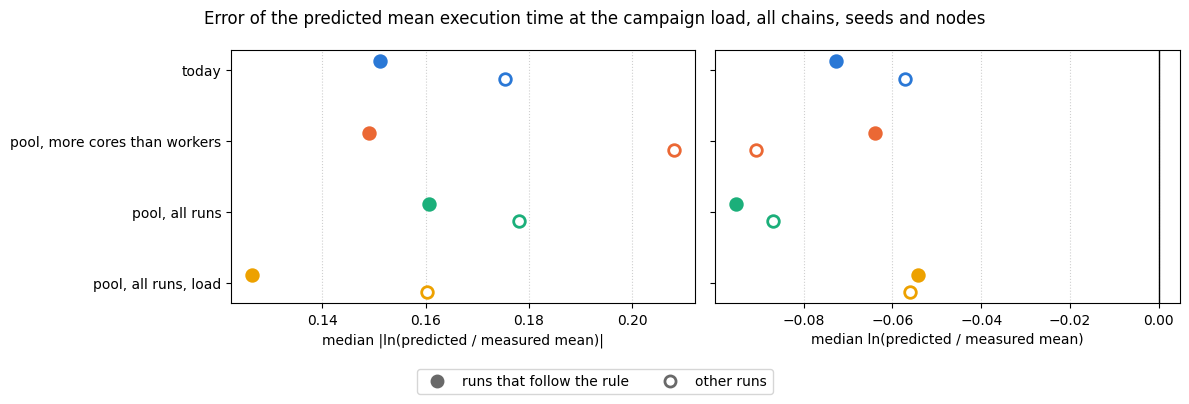

In [11]:
fig, (ax_abs, ax_bias) = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
positions = np.arange(len(MODELS))[::-1]
for ax, statistic, label in ((ax_abs, "abs_error", "median |ln(predicted / measured mean)|"), (ax_bias, "log_ratio", "median ln(predicted / measured mean)")):
    for row, model in zip(positions, MODELS):
        for rule, face in ((True, MODEL_COLORS[model]), (False, "white")):
            value = gp_errors[(gp_errors["model"] == model) & (gp_errors["follows_rule"] == rule)][statistic].median()
            ax.scatter(value, row + (0.12 if rule else -0.12), s=70, facecolor=face, edgecolor=MODEL_COLORS[model], linewidth=2, zorder=3)
    ax.set_xlabel(label)
    ax.grid(True, axis="x", linestyle=":", alpha=0.6)
ax_bias.axvline(0, color="black", linewidth=1)
ax_abs.set_yticks(positions, list(MODELS))
legend = [plt.Line2D([], [], linestyle="", marker="o", markersize=8, markerfacecolor=face, markeredgecolor="dimgray", markeredgewidth=2)
          for face in ("dimgray", "white")]
fig.legend(legend, ["runs that follow the rule", "other runs"], loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2)
fig.suptitle("Error of the predicted mean execution time at the campaign load, all chains, seeds and nodes")
plt.tight_layout()
plt.show()

What did the model with load learn? The next figure shows its predicted mean X over the load per worker, for the three
services of chain `04e` under the first seed. It shows one line for the configurations of the chain's runs with at most
one core per worker, and one for those with more. Each line is the median over these configurations of the prediction
divided by the prediction at the lowest load, so 1 means no slowdown. The gray band is the range of loads in the
training runs. Outside the band, the GP extrapolates and returns toward its average.

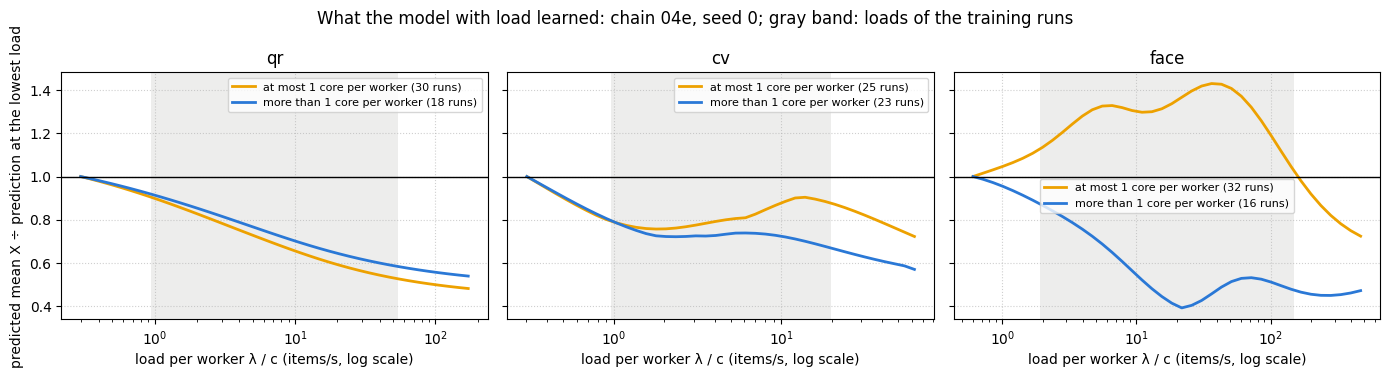

In [12]:
example_chain = "04e-chain-qr-cv-face"
fit = fitted["pool, all runs, load"][(example_chain, seeds[0])]
servers = truths[(example_chain, seeds[0], "campaign load")]["servers"]
fig, axes = plt.subplots(1, len(fit["training"]), figsize=(14, 3.8), sharey=True)
for k, (ax, (node, part)) in enumerate(zip(axes, fit["training"].items())):
    trained = 10 ** part["inputs"]["log10_load_per_worker"]
    loads = np.logspace(np.log10(trained.min()) - 0.5, np.log10(trained.max()) + 0.5, 40)
    relative = load_response(fit["models"][node], part, servers[:, k], loads)
    relative = relative / relative[:, :1]
    few_cores = (part["chain"]["cores"] / part["chain"]["parallelism"]).to_numpy() <= 1
    ax.axvspan(trained.min(), trained.max(), color=REFERENCE_COLOR, alpha=0.15, linewidth=0)
    for group, color, label in ((few_cores, MODEL_COLORS["pool, all runs, load"], "at most 1 core per worker"), (~few_cores, MODEL_COLORS["today"], "more than 1 core per worker")):
        if group.any():
            ax.plot(loads, np.median(relative[group], axis=0), color=color, linewidth=2, label=f"{label} ({group.sum()} runs)")
    ax.axhline(1.0, color="black", linewidth=1)
    ax.set_xscale("log")
    ax.set_xlabel("load per worker λ / c (items/s, log scale)")
    ax.set_title(node)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(fontsize=8)
axes[0].set_ylabel("predicted mean X ÷ prediction at the lowest load")
fig.suptitle(f"What the model with load learned: chain {short(example_chain)}, seed {seeds[0]}; gray band: loads of the training runs")
plt.tight_layout()
plt.show()

Was the load of a training run independent of how fast its configuration is? The table below has one row per service
of the chains (training runs of the first seed). It gives the correlation between log10 of the load per worker and the
logarithm of the run's mean X, and the 10th, 50th and 90th percentile of the run's utilization (load per worker × mean
X). If the campaign had chosen the load independently of the configuration, the correlation would be near 0. A clearly
negative correlation means that fast configurations were run at higher loads, so load per worker also tells the GP how
fast the configuration is.

In [13]:
confounding = {}
for (chain, s), fit in fitted["pool, all runs, load"].items():
    if s != seeds[0]:
        continue
    for node, part in fit["training"].items():
        service = f"{node} ({short(chain)})"
        log_load, log_mean = part["inputs"]["log10_load_per_worker"].to_numpy(), np.log(part["mean"])
        run_utilization = 10 ** log_load * part["mean"]
        confounding[service] = {"correlation of log load and log mean X": np.corrcoef(log_load, log_mean)[0, 1],
                                **{f"utilization, p{q}": np.percentile(run_utilization, q) for q in (10, 50, 90)}}
confounding = pd.DataFrame(confounding).T
confounding.round(2)

,correlation of log load and log mean X,"utilization, p10","utilization, p50","utilization, p90"
anomaly (04a),-0.06,0.00,0.04,0.40
agg (04a),-0.39,0.02,0.05,0.13
camera (04b),-0.00,0.00,0.05,0.48
qr (04b),-0.40,0.03,0.10,0.32
logs (04c),-0.36,0.03,0.10,0.29
tables (04c),-0.21,0.09,0.21,0.43
lidar (04d),0.01,0.00,0.01,0.05
agg (04d),-0.15,0.01,0.04,0.16
qr (04e),-0.24,0.03,0.09,0.29
cv (04e),-0.26,0.03,0.19,0.34


In [14]:
other = {model: error_table.loc[model, "median |error|, other runs"] for model in MODELS}
rule = {model: error_table.loc[model, "median |error|, runs that follow the rule"] for model in MODELS}
bias_other = {model: error_table.loc[model, "median error, other runs"] for model in MODELS}
best_other, best_rule = min(other, key=other.get), min(rule, key=rule.get)
display(Markdown(
    "**What this shows** (campaign load, all chains, seeds and nodes):\n\n"
    f"- **Runs that follow the rule.** The median absolute error is "
    + ", ".join(f"{rule[m]:.3f} for {m}" for m in MODELS) + f"; the smallest is that of {best_rule}. "
    "These runs are where the assumption that `parallelism` does not change X can be tested: compare the pool models with today's model.\n"
    f"- **Other runs (at most one core per worker somewhere).** The median absolute error is "
    + ", ".join(f"{other[m]:.3f} for {m}" for m in MODELS) + f"; the smallest is that of {best_other}. "
    f"The model trained only on runs that follow the rule has a median error of {bias_other['pool, more cores than workers']:+.3f} here "
    f"(a factor of {np.exp(bias_other['pool, more cores than workers']):.2f}), against {bias_other['today']:+.3f} for today's model: "
    "it has never seen a worker with one core or less.\n"
    f"- **Load stands in for the configuration.** The correlation between log load per worker and log mean X in the training runs lies "
    f"between {confounding.iloc[:, 0].min():+.2f} and {confounding.iloc[:, 0].max():+.2f} across the services "
    f"({(confounding.iloc[:, 0] < 0).sum()} of {len(confounding)} negative): the campaign ran fast configurations at higher loads. "
    "The GP with load therefore partly learns \"high load means a fast configuration\". In the figure of what it learned, a line that "
    "falls with the load shows exactly this, and it is the opposite of a slowdown by competing workers. A slowdown with load "
    "cannot be separated from this confound with this campaign; it needs every configuration measured at several loads."))

**What this shows** (campaign load, all chains, seeds and nodes):

- **Runs that follow the rule.** The median absolute error is 0.151 for today, 0.149 for pool, more cores than workers, 0.161 for pool, all runs, 0.126 for pool, all runs, load; the smallest is that of pool, all runs, load. These runs are where the assumption that `parallelism` does not change X can be tested: compare the pool models with today's model.
- **Other runs (at most one core per worker somewhere).** The median absolute error is 0.175 for today, 0.208 for pool, more cores than workers, 0.178 for pool, all runs, 0.160 for pool, all runs, load; the smallest is that of pool, all runs, load. The model trained only on runs that follow the rule has a median error of -0.091 here (a factor of 0.91), against -0.057 for today's model: it has never seen a worker with one core or less.
- **Load stands in for the configuration.** The correlation between log load per worker and log mean X in the training runs lies between -0.45 and +0.03 across the services (21 of 23 negative): the campaign ran fast configurations at higher loads. The GP with load therefore partly learns "high load means a fast configuration". In the figure of what it learned, a line that falls with the load shows exactly this, and it is the opposite of a slowdown by competing workers. A slowdown with load cannot be separated from this confound with this campaign; it needs every configuration measured at several loads.

## 4. Bounds for chains of pools

How do the bounds of Pegasus change when every service is a pool? A pool with c workers is faster than one server with
the same X: it serves up to c items at the same time, so its capacity is c / E[X] instead of 1 / E[X]. Today's bounds
model one server per service. They remain valid for a pool, because a pool never makes an item wait longer than one
server would, but they see a pool of c workers as one server at c times the pool's utilization, which can be overloaded at
B.1 load.

- **4a. Single-server bounds (baseline):** today's two versions of Pegasus, with today's model.
- **4b. Union bound over lane nodes:** the per-node bound of Pegasus, with every pool replaced by c single-server
  lanes.
- **4c. Network service bound over lanes:** Pegasus SNC with the same lanes.
- **4d. Today's model on today's emulation (reference):** what `2_evaluation.ipynb` computes, one server per service,
  for comparison with today's results.
- **4z. Results.**

**Lanes.** Replace a pool of c workers by c separate FIFO servers, the lanes, and send item i to lane i mod c. A lane
receives every c-th item, so the gap between its arrivals is the sum of c gaps of the arrival process. For Poisson
arrivals at rate λ, that sum is gamma-distributed with shape c and mean c / λ. This is the gamma process of `bounds.py`
with rate λ / c and squared coefficient of variation 1 / c, so the existing bounds apply to a lane unchanged.

The lanes are never better than the pool in the latency quantile: the pool lets any free worker take the next item,
while a lane waits for its own server. For one node this is a classical comparison of FIFO multi-server queues with
cyclic assignment. For chains it is only supported by simulation (the check in `pegasus/multi_server.py` and the
coverage below), not proved. It does not hold per item: a lane can let an item start before an item that arrived
earlier and waits in another lane.

The setup cell holds the container `bounds`, keyed by (bound, model, chain, seed, setting), with one end-to-end bound
per run of the chain in seconds.

In [15]:
bounds = {}
workload_of = lambda truth: dict(process="poisson", rate=truth["rates"], jitter=0.1)
nodes_of = {chain: len(chain_path(chain)[0]) for chain in chains}

### 4a. Single-server bounds (baseline)

Both versions of Pegasus from `2_evaluation.ipynb`, with today's model (3a), applied as if every service were one
server:

- **Per node**: the closed-form martingale bound of every node at α / K, added (union bound). Every node after the
  first uses the spacing that the node before gives its items.
- **Network service bound**: one Chernoff bound for the whole chain at α, with independent nodes.

Both are guarantees for single servers, and remain valid for pools. Where the pessimistic mean of a node puts the single
server at a utilization of 1 or more, the bound is infinite.

In [16]:
for (chain, s), fit in fitted["today"].items():
    K = nodes_of[chain]
    for setting in rates_of:
        truth, (beliefs, lower_means, _) = truths[(chain, s, setting)], fit[setting]
        bounds[("single server, per node", "today", chain, s, setting)] = martingale_closed_form_node_bounds(
            beliefs, lower_means, epsilon=alpha / K, **workload_of(truth)).sum(axis=0)
        bounds[("single server, network", "today", chain, s, setting)] = network_service_bound(
            beliefs, epsilon=alpha, holder_exponents=[1] * K, **workload_of(truth))

### 4b. Union bound over lane nodes

The per-node bound of 4a, with the lane process in place of the arrival process. A pool of c workers is bounded as one
lane receiving gamma arrivals at rate λ / c with squared coefficient of variation 1 / c, at α / K per node.

Spacing by the node before: a node with one worker releases items at least one execution time apart. So a lane of the
next node with c workers receives its items at least c execution times of the node before apart. A node with several
workers can release items at almost the same time, so after such a node no spacing is used. The bound is computed for
every model of Section 3.

In [17]:
for model, fits in fitted.items():
    for (chain, s), fit in fits.items():
        for setting in rates_of:
            truth, (beliefs, lower_means, _) = truths[(chain, s, setting)], fit[setting]
            bounds[("lanes, per node", model, chain, s, setting)] = lane_martingale_node_bounds(
                beliefs, lower_means, truth["servers"], epsilon=alpha / nodes_of[chain], **workload_of(truth)).sum(axis=0)

### 4c. Network service bound over lanes

The network service bound of 4a, where node k with c_k workers uses the lane transform. Its moment generating function
of the gap between arrivals, E[exp(−θT)], is raised to the power c_k. With the same number of workers at every node, the
chain decomposes into c lanes that each pass through every node, and the single-server proof applies to every lane.
With different numbers of workers per node, this decomposition does not exist, and the bound is not proved. It assumes,
like Pegasus SNC, that the execution times of an item are independent between the nodes.

In [18]:
for model, fits in fitted.items():
    for (chain, s), fit in fits.items():
        for setting in rates_of:
            truth = truths[(chain, s, setting)]
            bounds[("lanes, network", model, chain, s, setting)] = lane_network_bound(fit[setting][0], truth["servers"], epsilon=alpha, **workload_of(truth))

### 4d. Today's model on today's emulation (reference)

What `2_evaluation.ipynb` computes for these chains at B.1 load: the ground truth with one server per service
(`real_chain_data`), today's model (`fit_services`), and both versions of Pegasus (`pegasus_bound`,
`pegasus_snc_bound`). Its ground truth differs from that of this notebook, so it is compared only through coverage and
tightness, which are ratios to each setting's own truth. It shows how today's results compare with those for pools.

In [19]:
reference = {}   # (bound, chain, seed) -> case_statistics against today's single-server ground truth
for chain in chains:
    follows_rule = chain_servers(chain)[1]
    for s in seeds:
        data = real_chain_data(chain, level=1 - alpha, coverage_check=coverage_check, seed=[seed, s], utilization=utilization)
        models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
        single_truth = dict(measured=data.measured, measured_low=data.measured_low, follows_rule=follows_rule)
        reference[("per node", chain, s)] = case_statistics(pegasus_bound(data, models, alpha), single_truth)
        reference[("network", chain, s)] = case_statistics(pegasus_snc_bound(data, models, alpha), single_truth)

### 4z. Results: coverage and tightness

Each row of the table is one bound with one model in one setting, over all cases (8 chains × 10 seeds):

- **cases holding**: the share of cases in which the bound covers at least `confidence` of the runs. A chain with n
  runs fails as soon as more than ⌊n · (1 − `confidence`)⌋ of them are missed, for example more than 2 of 50 runs. One
  missed run more or less flips a case, so the next columns are given as well;
- **mean coverage** and **lowest coverage**: over the cases;
- **mean missed runs**: the mean number of runs per case whose bound lies below the lower edge of the confidence
  interval of the measured quantile;
- **median tightness**: bound ÷ measured p95, median over the runs of a case, then over the cases; inf where a case
  has infinite bounds for half of its runs or more;
- **median finite share**: the share of runs with a finite bound;
- **lowest coverage, runs that follow the rule / other runs**: the lowest coverage over the cases on these two groups of
  runs.

The Oracle (measured node quantiles added) and the reference of 4d are listed for comparison.

In [20]:
rows = [dict(setting=setting, bound=bound, model=model, chain=short(chain), seed=s, **case_statistics(value, truths[(chain, s, setting)]))
        for (bound, model, chain, s, setting), value in bounds.items()]
rows += [dict(setting=setting, bound="Oracle", model="measured nodes", chain=short(chain), seed=s, **case_statistics(truths[(chain, s, setting)]["oracle"], truths[(chain, s, setting)]))
         for chain in chains for s in seeds for setting in rates_of]
rows += [dict(setting="B.1 load, one server per service", bound=f"single server, {bound}", model="today", chain=short(chain), seed=s, **statistics)
         for (bound, chain, s), statistics in reference.items()]
runs_of = {short(chain): len(chain_servers(chain)[0]) for chain in chains}
cases = pd.DataFrame(rows).assign(holds=lambda table: table["coverage"] >= confidence,
                                  missed=lambda table: np.round((1 - table["coverage"]) * table["chain"].map(runs_of)))
cases.to_csv(output / "multi_server_prototype_cases.csv", index=False)

summary = cases.groupby(["setting", "bound", "model"], sort=False).agg(
    cases_holding=("holds", "mean"), mean_coverage=("coverage", "mean"), lowest_coverage=("coverage", "min"), mean_missed_runs=("missed", "mean"),
    median_tightness=("tightness", "median"),
    median_finite_share=("finite", "median"), lowest_coverage_rule_runs=("coverage_rule", "min"), lowest_coverage_other_runs=("coverage_other", "min"))
summary.round(2)

cases_holding  \
setting                          bound                   model                                          
B.1 load                         single server, per node today                                   1.00   
                                 single server, network  today                                   1.00   
campaign load                    single server, per node today                                   1.00   
                                 single server, network  today                                   1.00   
B.1 load                         lanes, per node         today                                   0.96   
campaign load                    lanes, per node         today                                   0.85   
B.1 load                         lanes, per node         pool, more cores than workers           0.95   
campaign load                    lanes, per node         pool, more cores than workers           0.72   
B.1 load                         lanes, per node         pool, all runs                          0.89   
campaign load                    lanes, per node         pool, all runs                          0.79   
B.1 load                         lanes, per node         pool, all runs, load                    0.75   
campaign load                    lanes, per node         pool, all runs, load                    0.68   
B.1 load                         lanes, network          today                                   0.99   
campaign load                    lanes, network          today                                   0.78   
B.1 load                         lanes, network          pool, more cores than workers           0.99   
campaign load                    lanes, network          pool, more cores than workers           0.70   
B.1 load                         lanes, network          pool, all runs                          0.91   
campaign load                    lanes, network          pool, all runs                          0.62   
B.1 load                         lanes, network          pool, all runs, load                    0.89   
campaign load                    lanes, network          pool, all runs, load                    0.60   
B.1 load                         Oracle                  measured nodes                          1.00   
campaign load                    Oracle                  measured nodes                          1.00   
B.1 load, one server per service single server, per node today                                   0.95   
                                 single server, network  today                                   0.99   

                                                                                        mean_coverage  \
setting                          bound                   model                                          
B.1 load                         single server, per node today                                   1.00   
                                 single server, network  today                                   1.00   
campaign load                    single server, per node today                                   1.00   
                                 single server, network  today                                   1.00   
B.1 load                         lanes, per node         today                                   0.99   
campaign load                    lanes, per node         today                                   0.98   
B.1 load                         lanes, per node         pool, more cores than workers           0.99   
campaign load                    lanes, per node         pool, more cores than workers           0.97   
B.1 load                         lanes, per node         pool, all runs                          0.98   
campaign load                    lanes, per node         pool, all runs                          0.97   
B.1 load                         lanes, per node         pool, all runs, load                    

The figure shows the main columns of the table for the two settings with pools. Every row is one bound with one model,
colored by the model. The left panel is the share of cases in which the bound holds; the target is 1. The right panel
is the median tightness on a log scale; 1 would be the measured p95, and smaller is better among bounds that hold. A
row without a marker on the right has infinite bounds for half of its runs or more in most cases. The gray rows are the
Oracle.

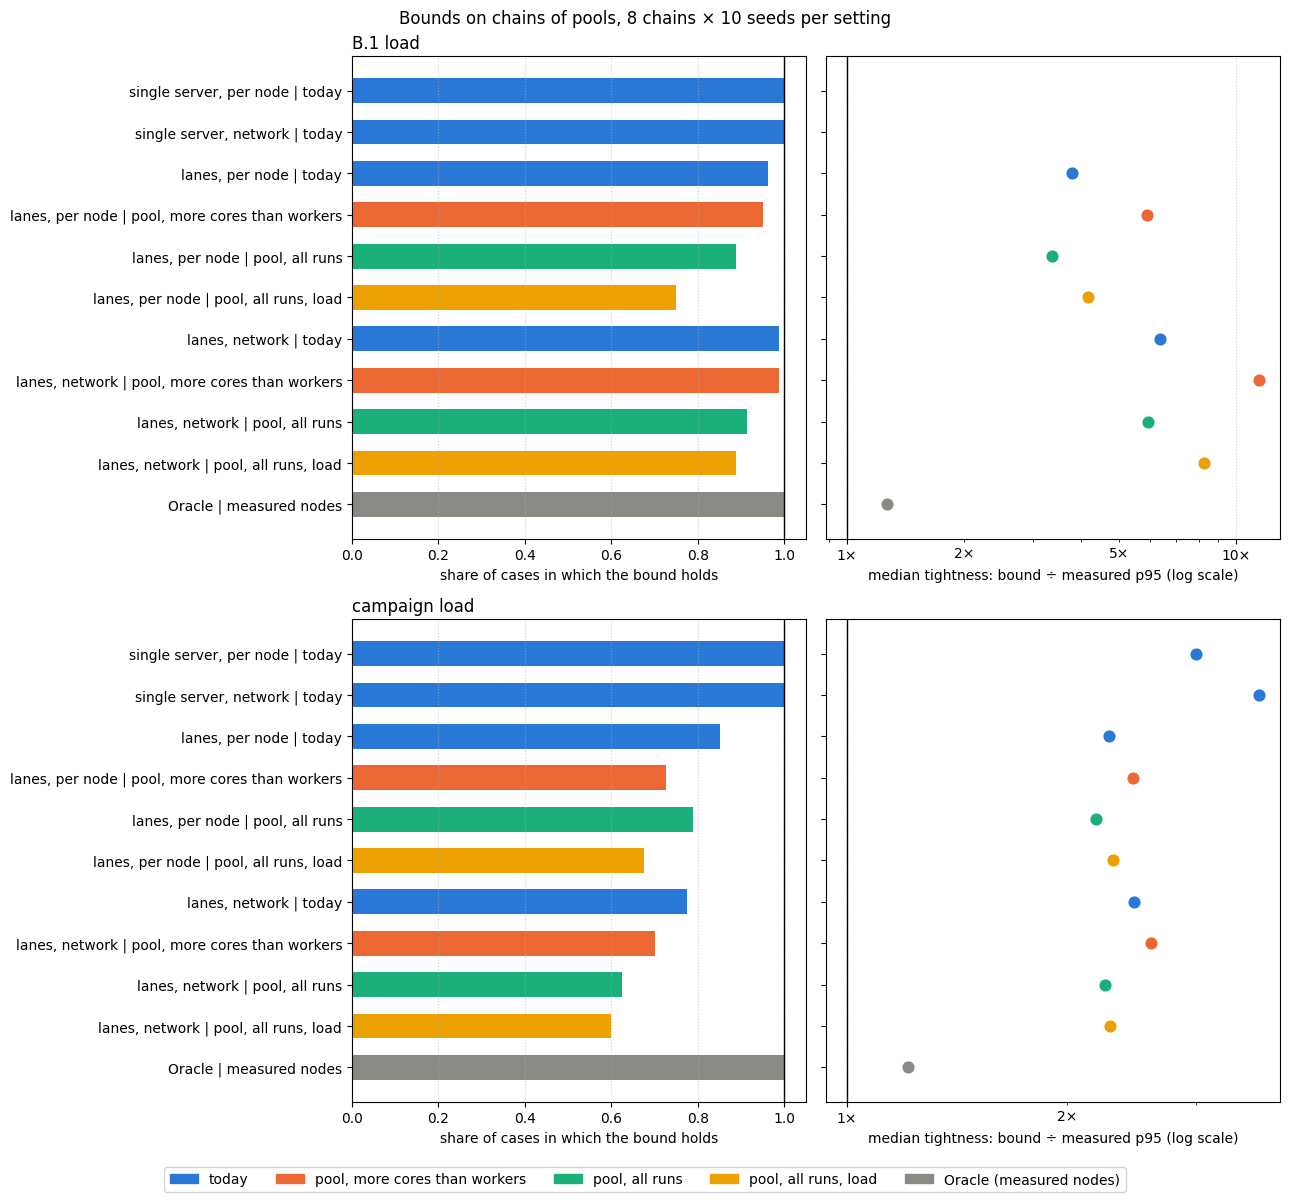

In [21]:
pool_settings = list(rates_of)
row_order = [(bound, model) for bound in ("single server, per node", "single server, network", "lanes, per node", "lanes, network") for model in MODELS
             if (pool_settings[0], bound, model) in summary.index] + [("Oracle", "measured nodes")]
fig, axes = plt.subplots(len(pool_settings), 2, figsize=(13, 0.42 * len(row_order) * len(pool_settings) + 2.5), sharey=True)
positions = np.arange(len(row_order))[::-1]
for (ax_holds, ax_tight), setting in zip(axes, pool_settings):
    for row, (bound, model) in zip(positions, row_order):
        line = summary.loc[(setting, bound, model)]
        color = MODEL_COLORS.get(model, REFERENCE_COLOR)
        ax_holds.barh(row, line["cases_holding"], color=color, height=0.6)
        if np.isfinite(line["median_tightness"]):
            ax_tight.scatter(line["median_tightness"], row, s=60, color=color, zorder=3)
    ax_holds.axvline(1.0, color="black", linewidth=1)
    ax_holds.set_xlim(0, 1.05)
    ax_holds.set_xlabel("share of cases in which the bound holds")
    ax_holds.set_title(setting, loc="left")
    ax_tight.axvline(1.0, color="black", linewidth=1)
    ax_tight.set_xscale("log")
    ax_tight.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:g}×"))
    ax_tight.xaxis.set_minor_formatter(plt.FuncFormatter(lambda value, _: f"{value:g}×" if str(f"{value:g}")[0] in "25" else ""))
    ax_tight.set_xlabel(f"median tightness: bound ÷ measured {p_label} (log scale)")
    for ax in (ax_holds, ax_tight):
        ax.grid(True, axis="x", linestyle=":", alpha=0.6)
axes[0][0].set_yticks(positions, [f"{bound} | {model}" for bound, model in row_order])
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in [*MODEL_COLORS.values(), REFERENCE_COLOR]]
fig.legend(handles, [*MODELS, "Oracle (measured nodes)"], loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=5)
fig.suptitle(f"Bounds on chains of pools, {len(chains)} chains × {len(seeds)} seeds per setting")
plt.tight_layout()
plt.show()

Per chain, for the union bound over lane nodes at B.1 load: the share of seeds in which the bound holds, and the median
tightness, for every model. This shows whether a model's failures concentrate on particular chains.

In [22]:
per_chain = (cases[(cases["setting"] == "B.1 load") & (cases["bound"] == "lanes, per node")]
             .groupby(["chain", "model"], sort=False).agg(holds=("holds", "mean"), tightness=("tightness", "median"))
             .unstack("model").round(2))
per_chain = per_chain.reindex(columns=[(what, model) for what in ("holds", "tightness") for model in MODELS])
per_chain

holds                                                                    \
model today pool, more cores than workers pool, all runs pool, all runs, load   
chain                                                                           
04a     1.0                           0.9            1.0                  0.9   
04b     0.8                           0.8            0.9                  0.4   
04c     1.0                           0.9            0.5                  0.2   
04d     0.9                           1.0            0.8                  0.6   
04e     1.0                           1.0            1.0                  1.0   
04f     1.0                           1.0            1.0                  1.0   
04g     1.0                           1.0            0.9                  0.9   
04h     1.0                           1.0            1.0                  1.0   

      tightness                                               \
model     today pool, more cores than workers pool, all runs   
chain                                                          
04a        4.06                          3.78           2.83   
04b        2.77                          2.67           2.98   
04c        4.19                         33.68           3.51   
04d        5.60                         15.95           3.91   
04e        2.49                          2.37           2.67   
04f        4.67                          7.10           3.91   
04g       48.75                           inf           5.93   
04h        3.76                          4.20           4.00   

                            
model pool, all runs, load  
chain                       
04a                  24.69  
04b                   2.46  
04c                   3.19  
04d                    inf  
04e                   2.22  
04f                   4.75  
04g                   7.57  
04h                   3.70

In [23]:
def line(setting, bound, model):
    return summary.loc[(setting, bound, model)]


def describe(setting, bound, model):
    entry = line(setting, bound, model)
    tightness = f"{entry['median_tightness']:.2f}×" if np.isfinite(entry["median_tightness"]) else "infinite"
    return (f"holds in {entry['cases_holding']:.0%} of the cases (mean coverage {entry['mean_coverage']:.3f}, {entry['mean_missed_runs']:.1f} missed runs "
            f"per case on average, lowest coverage {entry['lowest_coverage']:.2f}), "
            f"median tightness {tightness}, finite at {entry['median_finite_share']:.0%} of the runs")


b1, campaign, today_setting = "B.1 load", "campaign load", "B.1 load, one server per service"
text = [f"**What this shows** ({len(chains)} chains × {len(seeds)} seeds, Poisson arrivals, α = {alpha}):\n"]
text.append(f"- **Today's bounds do not fit pools.** At B.1 load, the single-server union bound with today's model "
            f"{describe(b1, 'single server, per node', 'today')}. It stays valid, but a pool of 2 workers looks like an overloaded server.")
text.append(f"- **Lanes restore finite bounds.** With today's model, the union bound over lane nodes at B.1 load {describe(b1, 'lanes, per node', 'today')}. "
            f"For comparison, today's union bound on today's single-server emulation {describe(today_setting, 'single server, per node', 'today')}.")
for model in list(MODELS)[1:]:
    text.append(f"- **{model}** (union bound over lane nodes): at B.1 load it {describe(b1, 'lanes, per node', model)}; "
                f"at the campaign load it {describe(campaign, 'lanes, per node', model)}.")
text.append(f"- **Network service bound over lanes** with the model with load: at B.1 load it {describe(b1, 'lanes, network', 'pool, all runs, load')}; "
            f"at the campaign load it {describe(campaign, 'lanes, network', 'pool, all runs, load')}.")
rule_runs = summary.xs("lanes, per node", level="bound")["lowest_coverage_rule_runs"]
text.append(f"- **Runs that follow the rule.** On these runs, the lowest coverage of the union bound over lane nodes over all models and both "
            f"settings is {rule_runs.min():.2f}; on the other runs it is "
            f"{summary.xs('lanes, per node', level='bound')['lowest_coverage_other_runs'].min():.2f}.")
display(Markdown("\n".join(text)))

**What this shows** (8 chains × 10 seeds, Poisson arrivals, α = 0.05):

- **Today's bounds do not fit pools.** At B.1 load, the single-server union bound with today's model holds in 100% of the cases (mean coverage 1.000, 0.0 missed runs per case on average, lowest coverage 0.98), median tightness infinite, finite at 42% of the runs. It stays valid, but a pool of 2 workers looks like an overloaded server.
- **Lanes restore finite bounds.** With today's model, the union bound over lane nodes at B.1 load holds in 96% of the cases (mean coverage 0.992, 0.4 missed runs per case on average, lowest coverage 0.94), median tightness 3.78×, finite at 78% of the runs. For comparison, today's union bound on today's single-server emulation holds in 95% of the cases (mean coverage 0.990, 0.5 missed runs per case on average, lowest coverage 0.94), median tightness 4.00×, finite at 78% of the runs.
- **pool, more cores than workers** (union bound over lane nodes): at B.1 load it holds in 95% of the cases (mean coverage 0.986, 0.7 missed runs per case on average, lowest coverage 0.92), median tightness 5.90×, finite at 69% of the runs; at the campaign load it holds in 72% of the cases (mean coverage 0.971, 1.4 missed runs per case on average, lowest coverage 0.90), median tightness 2.46×, finite at 92% of the runs.
- **pool, all runs** (union bound over lane nodes): at B.1 load it holds in 89% of the cases (mean coverage 0.984, 0.8 missed runs per case on average, lowest coverage 0.92), median tightness 3.36×, finite at 82% of the runs; at the campaign load it holds in 79% of the cases (mean coverage 0.971, 1.4 missed runs per case on average, lowest coverage 0.88), median tightness 2.19×, finite at 94% of the runs.
- **pool, all runs, load** (union bound over lane nodes): at B.1 load it holds in 75% of the cases (mean coverage 0.976, 1.1 missed runs per case on average, lowest coverage 0.92), median tightness 4.16×, finite at 70% of the runs; at the campaign load it holds in 68% of the cases (mean coverage 0.964, 1.7 missed runs per case on average, lowest coverage 0.88), median tightness 2.31×, finite at 94% of the runs.
- **Network service bound over lanes** with the model with load: at B.1 load it holds in 89% of the cases (mean coverage 0.984, 0.8 missed runs per case on average, lowest coverage 0.92), median tightness 8.27×, finite at 70% of the runs; at the campaign load it holds in 60% of the cases (mean coverage 0.958, 2.0 missed runs per case on average, lowest coverage 0.86), median tightness 2.29×, finite at 94% of the runs.
- **Runs that follow the rule.** On these runs, the lowest coverage of the union bound over lane nodes over all models and both settings is 0.91; on the other runs it is 0.82.

## 5. Conclusions and open questions

In [24]:
lane_today, lane_load = line(b1, "lanes, per node", "today"), line(b1, "lanes, per node", "pool, all runs, load")
lane_strict, lane_all = line(b1, "lanes, per node", "pool, more cores than workers"), line(b1, "lanes, per node", "pool, all runs")
best = max(list(MODELS)[1:], key=lambda model: (line(b1, "lanes, per node", model)["cases_holding"], -line(b1, "lanes, per node", model)["median_tightness"]))
display(Markdown(
    f"- **Pools need the lane bounds.** Today's single-server bounds stay valid for pools but are finite at only "
    f"{line(b1, 'single server, per node', 'today')['median_finite_share']:.0%} of the runs (median over the cases at B.1 load). The lane bounds "
    f"make them finite again: with today's model, the union bound over lane nodes has a median tightness of {lane_today['median_tightness']:.2f}×, "
    f"against {line(today_setting, 'single server, per node', 'today')['median_tightness']:.2f}× for today's union bound on today's single-server emulation.\n"
    f"- **Among the models without `parallelism`**, the one that holds most often at B.1 load, and is tighter on ties, is **{best}**. "
    f"Union bound over lane nodes at B.1 load: holds in {lane_strict['cases_holding']:.0%} (more cores than workers), "
    f"{lane_all['cases_holding']:.0%} (all runs) and {lane_load['cases_holding']:.0%} (all runs, load) of the cases, against "
    f"{lane_today['cases_holding']:.0%} for today's model with `parallelism` as an input.\n"
    f"Missed runs per case on average: {lane_today['mean_missed_runs']:.1f} for today's model, and "
    f"{lane_strict['mean_missed_runs']:.1f}, {lane_all['mean_missed_runs']:.1f} and {lane_load['mean_missed_runs']:.1f} for the three pool models.\n"
    f"- **At the campaign load, every lane bound holds less often**, also with today's model: "
    f"{line(campaign, 'lanes, per node', 'today')['cases_holding']:.0%} against {lane_today['cases_holding']:.0%} at B.1 load (union bound over "
    "lane nodes). At this light load the latency is mostly execution time, so a predicted mean that is too low is no longer hidden by "
    "slack in the queueing part of the bound. The median error of the predicted mean is "
    + ", ".join(f"{error_table.loc[model, 'median error, other runs']:+.3f}" for model in MODELS)
    + " for the four models on the runs that break the rule"
    + (": every model predicts the runs of the chains as faster than they are.\n"
       if all(error_table.loc[model, "median error, other runs"] < 0 for model in MODELS) else " (Section 3z).\n")
    + f"- **Error of the predicted mean on the runs that break the rule** (Section 3z, median absolute error): "
    + ", ".join(f"{model} {error_table.loc[model, 'median |error|, other runs']:.3f}" for model in MODELS) + ".\n"
    f"- **The load input and its confound.** With load as an input, the median absolute error on the runs that break the rule is "
    f"{error_table.loc['pool, all runs, load', 'median |error|, other runs']:.3f}, against {error_table.loc['pool, all runs', 'median |error|, other runs']:.3f} "
    f"without it; the union bound over lane nodes holds in {lane_load['cases_holding']:.0%} of the cases at B.1 load, against "
    f"{lane_all['cases_holding']:.0%} without it. Load per worker and the speed of the configuration are correlated in the training runs "
    f"(correlations between {confounding.iloc[:, 0].min():+.2f} and {confounding.iloc[:, 0].max():+.2f}), so the GP learns \"high load, fast "
    "configuration\". In a chain, every node gets the rate that its busiest node allows, so a slow node that is not the busiest one gets a "
    "high load per worker and is predicted too fast."))

- **Pools need the lane bounds.** Today's single-server bounds stay valid for pools but are finite at only 42% of the runs (median over the cases at B.1 load). The lane bounds make them finite again: with today's model, the union bound over lane nodes has a median tightness of 3.78×, against 4.00× for today's union bound on today's single-server emulation.
- **Among the models without `parallelism`**, the one that holds most often at B.1 load, and is tighter on ties, is **pool, more cores than workers**. Union bound over lane nodes at B.1 load: holds in 95% (more cores than workers), 89% (all runs) and 75% (all runs, load) of the cases, against 96% for today's model with `parallelism` as an input.
Missed runs per case on average: 0.4 for today's model, and 0.7, 0.8 and 1.1 for the three pool models.
- **At the campaign load, every lane bound holds less often**, also with today's model: 85% against 96% at B.1 load (union bound over lane nodes). At this light load the latency is mostly execution time, so a predicted mean that is too low is no longer hidden by slack in the queueing part of the bound. The median error of the predicted mean is -0.057, -0.091, -0.087, -0.056 for the four models on the runs that break the rule: every model predicts the runs of the chains as faster than they are.
- **Error of the predicted mean on the runs that break the rule** (Section 3z, median absolute error): today 0.175, pool, more cores than workers 0.208, pool, all runs 0.178, pool, all runs, load 0.160.
- **The load input and its confound.** With load as an input, the median absolute error on the runs that break the rule is 0.160, against 0.178 without it; the union bound over lane nodes holds in 75% of the cases at B.1 load, against 89% without it. Load per worker and the speed of the configuration are correlated in the training runs (correlations between -0.45 and +0.03), so the GP learns "high load, fast configuration". In a chain, every node gets the rate that its busiest node allows, so a slow node that is not the busiest one gets a high load per worker and is predicted too fast.

Open questions, independent of the numbers above:

- **Proof for chains.** The lane bounds are proved for one node. For chains they rest on simulation, and the network
  service bound over lanes has no proof when nodes have different numbers of workers.
- **Larger pools.** The campaign's chains have at most a few workers per node (Section 2). The lanes ignore that any
  free worker can take the next item, so they get looser as c grows; this should be measured with larger pools.
- **A campaign that follows the rule.** Few runs have more cores than workers, so the cleanest test of "X does not
  depend on `parallelism`" rests on few runs per chain.
- **Load and execution time together.** The model with load predicts the average slowdown at a load, but the bounds
  still assume that the X of an item is independent of the queue it waits in. With shared cores, slow items come in
  busy periods. A ground truth whose X depends on the current number of busy workers, instead of replayed times, would
  test this.
- **Release once per second.** The campaign's services released items once per second, so its measured slowdowns
  come from bursty arrivals; the testbed change to continuous release would remove this.